<a href="https://colab.research.google.com/github/renoegneo/MLclasswork/blob/main/ML_Practical_10_Variant_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving ПР_10_—_для_студентов_данные_+_шаблон_A.zip to ПР_10_—_для_студентов_данные_+_шаблон_A.zip


In [ ]:

import zipfile
import os

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/pr10')

print(os.listdir('/content/pr10'))


['customers.csv', 'README.txt', 'pr10_template_A.ipynb']


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = pd.read_csv('/content/pr10/customers.csv')

print("Размер датасета:", df.shape)
display(df.head())


Размер датасета: (600, 5)


,client_id,avg_check,purchases_month,days_since_last,discount_share
0,1,862,7.5,7,0.73
1,2,1995,0.8,80,0.32
2,3,2898,5.1,4,0.09
3,4,1017,9.6,10,0.64
4,5,715,9.2,7,0.68


In [ ]:

# Проверяем пропущенные значения
print("Пропущенные значения:")
print(df.isnull().sum())

# Удаляем ID клиента, так как он не влияет на поведение
X = df.drop(columns=['client_id'])

# Масштабируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nРазмер подготовленных данных:", X_scaled.shape)
print("Подготовка завершена!")


Пропущенные значения:
client_id          0
avg_check          0
purchases_month    0
days_since_last    0
discount_share     0
dtype: int64

Размер подготовленных данных: (600, 4)
Подготовка завершена!


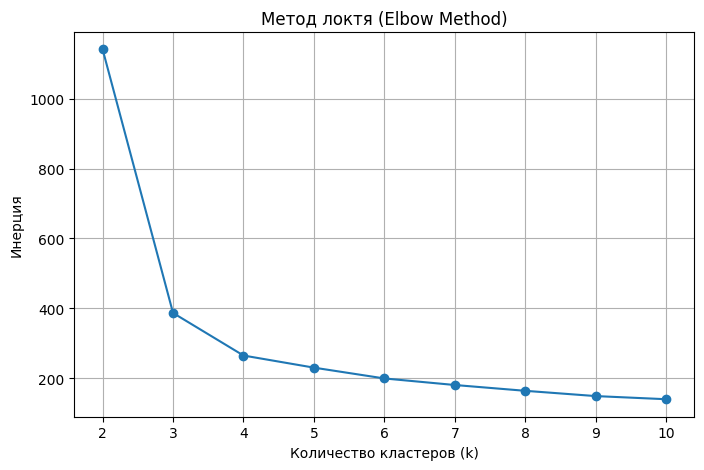

In [ ]:

inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')
plt.title('Метод локтя (Elbow Method)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Инерция')
plt.xticks(range(2, 11))
plt.grid()
plt.show()


k = 2, Silhouette Score = 0.5288
k = 3, Silhouette Score = 0.6674
k = 4, Silhouette Score = 0.6524
k = 5, Silhouette Score = 0.5002
k = 6, Silhouette Score = 0.3997
k = 7, Silhouette Score = 0.4012
k = 8, Silhouette Score = 0.3217
k = 9, Silhouette Score = 0.3176
k = 10, Silhouette Score = 0.3192


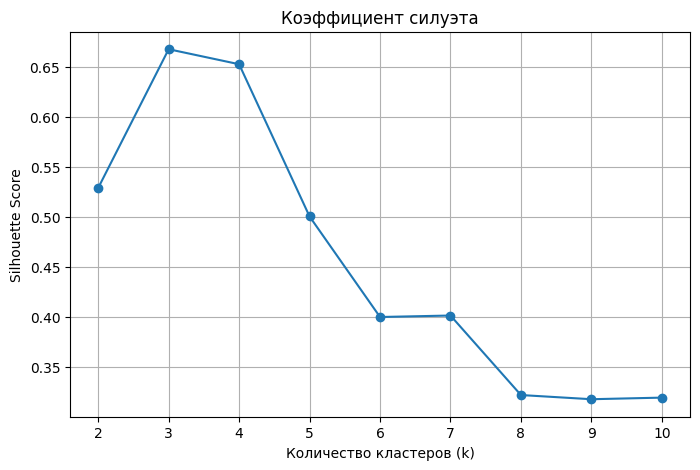

In [ ]:

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"k = {k}, Silhouette Score = {score:.4f}")

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Коэффициент силуэта')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid()
plt.show()


In [ ]:

# Создаём 3 кластера
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Количество клиентов в каждом кластере:")
print(df['Cluster'].value_counts().sort_index())

display(df.head(10))


Количество клиентов в каждом кластере:
Cluster
0    210
1    220
2    170
Name: count, dtype: int64


,client_id,avg_check,purchases_month,days_since_last,discount_share,Cluster
0,1,862,7.5,7,0.73,1
1,2,1995,0.8,80,0.32,2
2,3,2898,5.1,4,0.09,0
3,4,1017,9.6,10,0.64,1
4,5,715,9.2,7,0.68,1
5,6,5256,1.5,27,0.15,0
6,7,1049,7.8,4,0.62,1
7,8,1892,1.2,124,0.19,2
8,9,1249,7.7,8,0.57,1
9,10,5742,1.4,33,0.05,0


In [ ]:

# Средние значения признаков в каждом кластере
cluster_profiles = df.groupby('Cluster').mean(numeric_only=True)

display(cluster_profiles.round(2))


,client_id,avg_check,purchases_month,days_since_last,discount_share
Cluster,,,,,
0,294.07,5175.85,2.78,20.62,0.14
1,292.74,884.42,6.94,6.14,0.59
2,318.49,1543.98,0.70,91.95,0.33


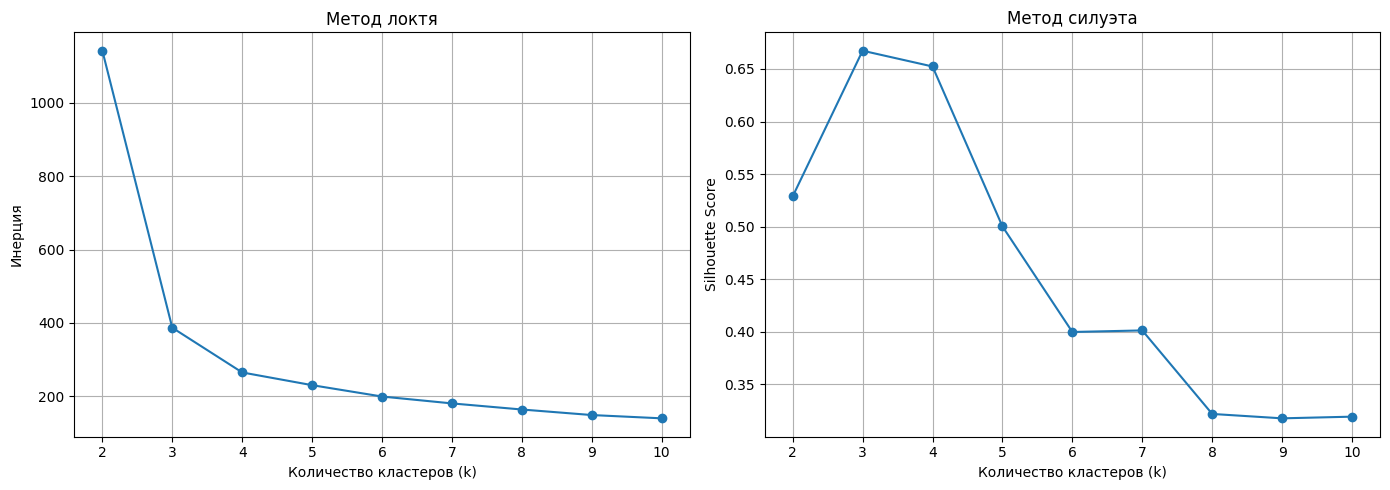

Оптимальное количество кластеров: 3


In [ ]:

# Строим два графика для сравнения критериев

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Метод локтя
axes[0].plot(range(2, 11), inertia, marker='o')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_ylabel('Инерция')
axes[0].set_xticks(range(2, 11))
axes[0].grid()

# Коэффициент силуэта
axes[1].plot(range(2, 11), silhouette_scores, marker='o')
axes[1].set_title('Метод силуэта')
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(range(2, 11))
axes[1].grid()

plt.tight_layout()
plt.show()

print("Оптимальное количество кластеров: 3")


In [ ]:

cluster_profiles = df.groupby('Cluster')[
    ['avg_check', 'purchases_month',
     'days_since_last', 'discount_share']
].mean().round(2)

print("ПРОФИЛИ КЛАСТЕРОВ")
display(cluster_profiles)


ПРОФИЛИ КЛАСТЕРОВ


,avg_check,purchases_month,days_since_last,discount_share
Cluster,,,,
0,5175.85,2.78,20.62,0.14
1,884.42,6.94,6.14,0.59
2,1543.98,0.70,91.95,0.33


In [ ]:

cluster_names = {
    0: 'Клиенты с высоким средним чеком',
    1: 'Активные покупатели со скидками',
    2: 'Редко покупающие клиенты'
}

df['Segment'] = df['Cluster'].map(cluster_names)

print("Распределение клиентов по сегментам:")
print(df['Segment'].value_counts())

display(df[['client_id', 'Cluster', 'Segment']].head(10))


Распределение клиентов по сегментам:
Segment
Активные покупатели со скидками    220
Клиенты с высоким средним чеком    210
Редко покупающие клиенты           170
Name: count, dtype: int64


,client_id,Cluster,Segment
0,1,1,Активные покупатели со скидками
1,2,2,Редко покупающие клиенты
2,3,0,Клиенты с высоким средним чеком
3,4,1,Активные покупатели со скидками
4,5,1,Активные покупатели со скидками
5,6,0,Клиенты с высоким средним чеком
6,7,1,Активные покупатели со скидками
7,8,2,Редко покупающие клиенты
8,9,1,Активные покупатели со скидками
9,10,0,Клиенты с высоким средним чеком


In [ ]:

# Первая кластеризация
kmeans_42 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
labels_42 = kmeans_42.fit_predict(X_scaled)

# Вторая кластеризация с другим random_state
kmeans_21 = KMeans(
    n_clusters=3,
    random_state=21,
    n_init=10
)
labels_21 = kmeans_21.fit_predict(X_scaled)

# Сравниваем состав кластеров
ari = adjusted_rand_score(labels_42, labels_21)

print("Random state 42 и 21")
print("Adjusted Rand Index:", round(ari, 4))

if ari == 1:
    print("Состав кластеров полностью совпадает.")
elif ari > 0.9:
    print("Состав кластеров практически не изменился.")
else:
    print("Состав кластеров изменился.")

# Таблица сравнения
comparison = pd.crosstab(
    pd.Series(labels_42, name='Random State 42'),
    pd.Series(labels_21, name='Random State 21')
)

display(comparison)


Random state 42 и 21
Adjusted Rand Index: 1.0
Состав кластеров полностью совпадает.


Random State 21,0,1,2
Random State 42,,,
0,0,0,210
1,0,220,0
2,170,0,0


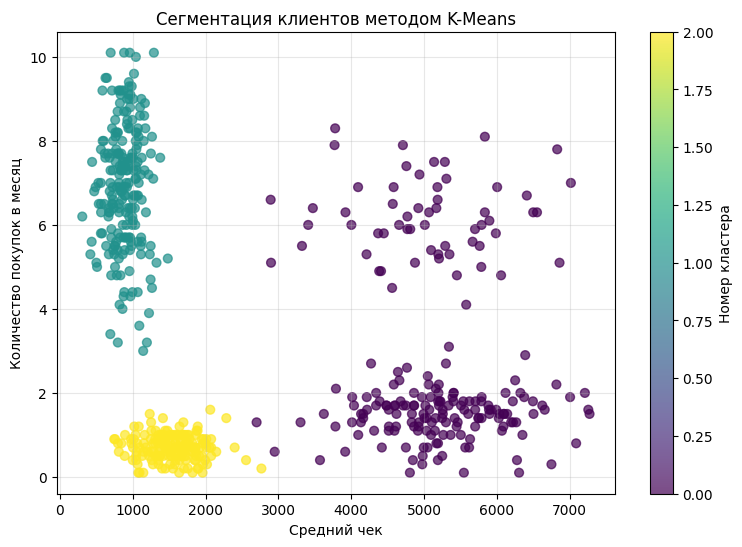

In [ ]:

plt.figure(figsize=(9, 6))

plt.scatter(
    df['avg_check'],
    df['purchases_month'],
    c=df['Cluster'],
    cmap='viridis',
    s=40,
    alpha=0.7
)

plt.title('Сегментация клиентов методом K-Means')
plt.xlabel('Средний чек')
plt.ylabel('Количество покупок в месяц')
plt.colorbar(label='Номер кластера')
plt.grid(alpha=0.3)
plt.show()


In [ ]:

df.to_csv(
    '/content/pr10_cluster_results.csv',
    index=False
)

print("Результаты сохранены!")


Результаты сохранены!


In [ ]:

from google.colab import files

files.download('/content/pr10_cluster_results.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Вывод по практической работе №10

В ходе практической работы была выполнена кластеризация клиентов магазина с использованием алгоритма K-Means.

Для анализа использовался датасет из 600 клиентов с признаками: средний чек, количество покупок в месяц, количество дней с последней покупки и доля покупок со скидкой.

В ходе работы:
1. Выполнена подготовка и масштабирование данных с помощью StandardScaler.
2. Построен график метода локтя для k от 2 до 10.
3. Рассчитан коэффициент силуэта для каждого значения k.
4. Выбрано оптимальное количество кластеров — **3**. Максимальный коэффициент силуэта составил **0.6674**.
5. Построены профили кластеров и выделены три сегмента:
   - Клиенты с высоким средним чеком.
   - Активные покупатели со скидками.
   - Редко покупающие клиенты.
6. Проверена устойчивость кластеризации с другим random_state. Значение Adjusted Rand Index составило **1.0**, что показывает полное совпадение состава кластеров.

**Общий вывод:** алгоритм K-Means позволил разделить клиентов на три понятные группы. Полученные результаты можно использовать для разработки персональных предложений, скидок и стратегий удержания клиентов.